# 03 · Exploring: What a Plot Is Actually For

A plot is not decoration and it is not a deliverable. It is a **question you're
asking the data**, and the only ones worth making are the ones where you'd act
differently depending on the answer.

This notebook asks five questions. Each has a decision attached.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

DATA = Path.cwd()
while not (DATA / "data" / "turbine_readings.csv").exists() and DATA != DATA.parent:
    DATA = DATA.parent
CSV = DATA / "data" / "turbine_readings.csv"
print("reading", CSV.relative_to(DATA))

reading data/turbine_readings.csv


In [2]:
df = pd.read_csv(CSV.parent / "turbine_clean.csv", parse_dates=["install_date"])
print(df.shape)
df.head(3)

(6035, 11)


,turbine_id,site,install_date,age_years,rotor_speed_rpm,vibration_mm_s,gearbox_temp_c,operating_hours,last_inspector,failed_within_90d,vibration_missing
0,T00567,Clyde,2019-05-12,7.23,11.99,0.5371,82.5,48806.0,s.tran,0,0
1,T02105,Ardrossan,2025-02-22,1.44,11.29,NaN,57.2,9944.0,m.lindqvist,0,1
2,T04536,Beinn an Tuirc,2024-07-18,2.04,13.44,0.1917,66.4,14513.0,m.lindqvist,0,0


## Question 1 · What shape is each variable?

Before any modelling: is it symmetric, skewed, bimodal, or bounded? The answer
decides whether the mean means anything and whether a transform would help.

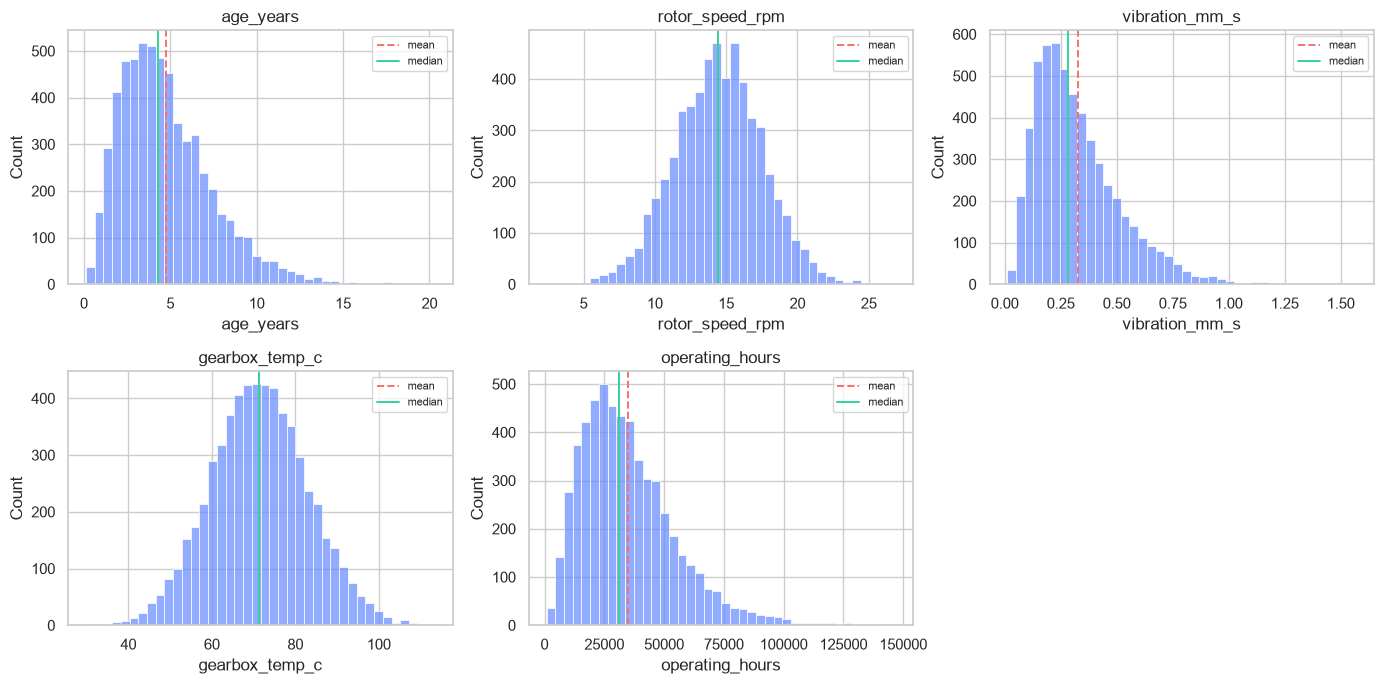

In [3]:
num = ["age_years", "rotor_speed_rpm", "vibration_mm_s", "gearbox_temp_c", "operating_hours"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, num):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, color="#6c8fff")
    ax.set_title(c)
    ax.axvline(df[c].mean(), color="#f87171", ls="--", lw=1.4, label="mean")
    ax.axvline(df[c].median(), color="#34d399", ls="-", lw=1.4, label="median")
    ax.legend(fontsize=8)
axes.flat[-1].axis("off")
plt.tight_layout()

### Read the gap between the two lines

Where the red mean sits noticeably right of the green median, the variable is
**right-skewed** — a long tail of high values pulling the average up. `age_years`
and `vibration_mm_s` both show this.

The decision it drives: for a skewed variable, "the average turbine" is a misleading
summary, and linear models may benefit from a log transform.

## Question 2 · Does the target relate to any of these?

This is the one that decides which features are worth having.

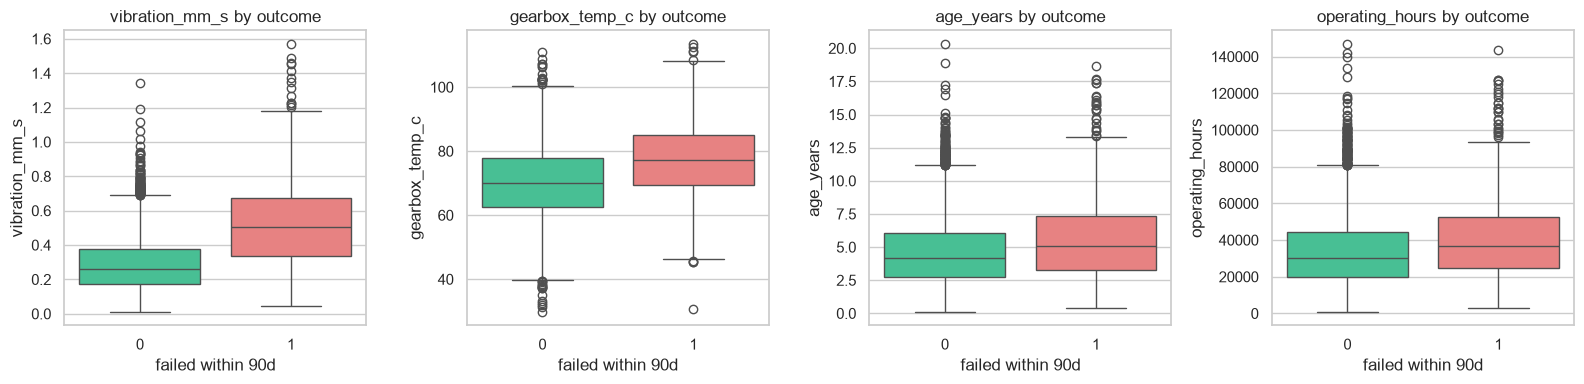

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, ["vibration_mm_s", "gearbox_temp_c", "age_years", "operating_hours"]):
    sns.boxplot(data=df, x="failed_within_90d", y=c, ax=ax,
                palette=["#34d399", "#f87171"], hue="failed_within_90d", legend=False)
    ax.set_title(f"{c} by outcome")
    ax.set_xlabel("failed within 90d")
plt.tight_layout()

In [5]:
df.groupby("failed_within_90d")[num].mean().round(3).T

failed_within_90d,0,1
age_years,4.610,5.599
rotor_speed_rpm,14.461,14.321
vibration_mm_s,0.291,0.526
gearbox_temp_c,70.292,77.432
operating_hours,33709.287,40823.487


Vibration and gearbox temperature separate the two groups clearly. Age separates
them mildly. Rotor speed barely at all.

That is a **feature-selection finding**, arrived at before fitting anything.

## Question 3 · Are the features telling us the same thing twice?

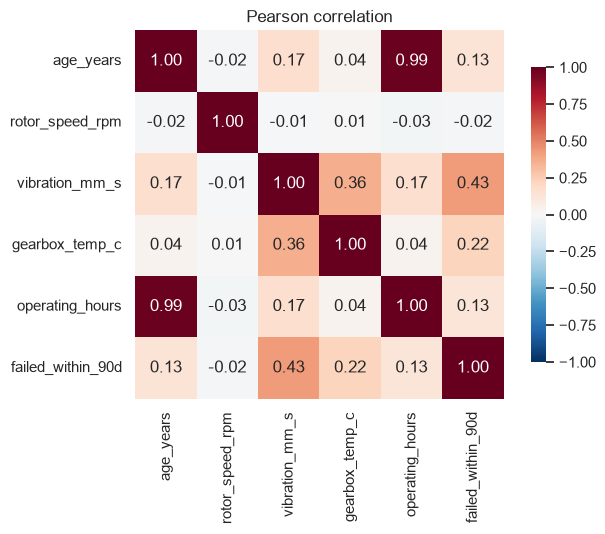

In [6]:
corr = df[num + ["failed_within_90d"]].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Pearson correlation")
plt.tight_layout()

`age_years` and `operating_hours` are almost perfectly correlated — unsurprising,
since hours accumulate with age. Two near-identical inputs make linear-model
coefficients unstable and uninterpretable, even while predictions stay fine.

Decision: keep one, or combine them into something new (hours per year of age
captures *intensity of use*, which the raw pair does not).

> **Correlation only detects straight-line relationships.** A strong curved
> relationship can show a correlation near zero. Never conclude "no relationship"
> from a low correlation without looking at the scatter.

In [7]:
df["hours_per_year"] = df["operating_hours"] / df["age_years"].clip(lower=0.1)
print(df.groupby("failed_within_90d")["hours_per_year"].mean().round(0))

failed_within_90d
0    7315.0
1    7314.0
Name: hours_per_year, dtype: float64


## Question 4 · Do the sites behave differently?

If they do, site is a real feature. If they don't, it's noise you're inviting the
model to overfit.

In [8]:
site = df.groupby("site").agg(
    turbines=("turbine_id", "count"),
    failure_rate=("failed_within_90d", "mean"),
    mean_vibration=("vibration_mm_s", "mean"),
    mean_age=("age_years", "mean"),
).round(3).sort_values("failure_rate", ascending=False)
site

,turbines,failure_rate,mean_vibration,mean_age
site,,,,
Clyde,1218,0.158,0.330,4.827
Ardrossan,2155,0.156,0.324,4.775
Beinn an Tuirc,897,0.153,0.325,4.760
Whitelee,1765,0.152,0.326,4.706


### Careful here

If one site has a higher failure rate *and* older turbines, site may be standing in
for age rather than carrying information of its own. Check before believing it.

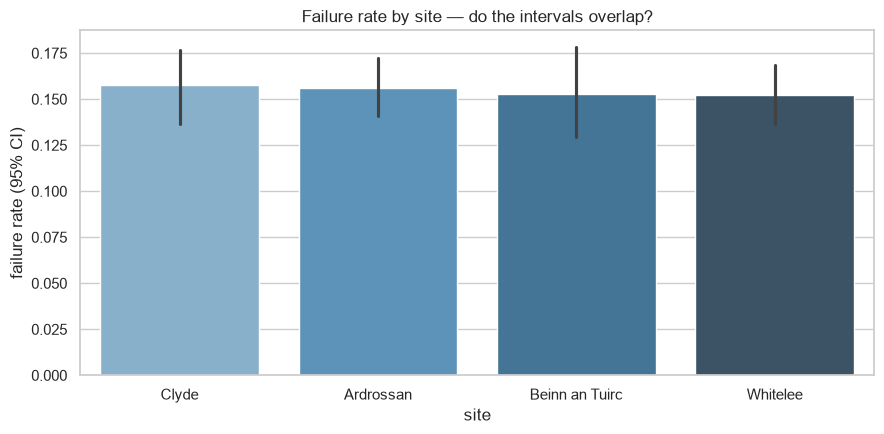

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=df, x="site", y="failed_within_90d", ax=ax,
            hue="site", palette="Blues_d", legend=False, errorbar=("ci", 95))
ax.set_ylabel("failure rate (95% CI)")
ax.set_title("Failure rate by site — do the intervals overlap?")
plt.tight_layout()

**Read the error bars.** Where confidence intervals overlap heavily, the apparent
difference between sites may be noise. This is the sample-size point from your
statistics course, applied to a bar chart — and the reason a bar chart without error
bars is frequently misleading.

## Question 5 · Does the missingness flag carry signal?

Notebook 02 kept `vibration_missing` as a feature on the grounds that the missingness
was informative. Confirm that.

In [10]:
print(df.groupby("vibration_missing")["failed_within_90d"].agg(["mean", "count"]).round(3))

overall = df["failed_within_90d"].mean()
lift = df.groupby("vibration_missing")["failed_within_90d"].mean() / overall
print(f"\nlift vs overall rate: {lift.round(2).to_dict()}")

                    mean  count
vibration_missing              
0                  0.149   5626
1                  0.240    409

lift vs overall rate: {0: 0.96, 1: 1.55}


A turbine with a missing vibration reading is substantially more likely to fail.
The *absence* of data is data. Keeping that flag was the right call.

---

## What this pass produced

- vibration and gearbox temperature are the strongest signals
- rotor speed looks close to useless
- age and operating hours are redundant — combine or drop one
- site differences may be confounded by age; needs care
- the missingness flag is genuinely predictive

None of that required fitting a model, and all of it shapes what you do next.

## Your turn

1. Plot `vibration_mm_s` against `gearbox_temp_c`, coloured by outcome. Is the
   boundary between classes roughly a straight line?
2. Compute the correlation between age and operating hours. Would you keep both?
3. Does `last_inspector` relate to failure? If it appears to, what would you check
   before believing it?